# Analysis
## 02 - Ableitungen: Einführung
Die Steigung einer Kurve

Die Ableitung ist eines der wichtigsten Konzepte der Mathematik. Sie beschreibt, wie schnell sich eine Funktion an einer bestimmten Stelle ändert - die **momentane Änderungsrate**.

### Lernziele

In diesem Abschnitt lernst Du:
- **Was eine Ableitung ist** und warum sie die Steigung einer Kurve beschreibt
- **Den Übergang von der Sekante zur Tangente** visuell zu verstehen
- **Die Ableitung numerisch zu berechnen** mithilfe der Grenzwertdefinition
- **Die Ableitung symbolisch zu berechnen** mit SymPy
- **Die verschiedenen Notationen** der Ableitung ($f'(x)$, $\frac{df}{dx}$, $\dot{f}$)

---

### 1. Die Kernidee: Von der durchschnittlichen zur momentanen Steigung

Bei einer Geraden, z.B. $y = 2x + 1$, ist die Steigung überall gleich. Für jeden Schritt in $x$ steigt $y$ um 2. Die Steigung ist konstant **2**.

Aber was ist mit einer Kurve wie $f(x) = x^2$? Die Steilheit dieser Funktion ändert sich ständig. Bei $x=10$ ist sie sehr steil, bei $x=0$ fast flach.

Die **Ableitung** einer Funktion an einer bestimmten Stelle ist die **Steigung der Kurve genau an diesem Punkt**.

#### Das Steigungsdreieck
Um die Steigung zu verstehen, beginnen wir mit dem **Steigungsdreieck** (auch: Differenzenquotient). Wir wählen zwei Punkte auf der Kurve und zeichnen eine Gerade durch sie - die **Sekante**. Ihre Steigung ist die *durchschnittliche* Änderungsrate zwischen diesen beiden Punkten.

Die Steigung einer Geraden zwischen zwei Punkten $(x_1, y_1)$ und $(x_2, y_2)$ ist:
$$
m = \frac{\Delta y}{\Delta x} = \frac{y_2 - y_1}{x_2 - x_1}
$$

In Funktionsnotation: Wenn wir einen Punkt $x$ und einen zweiten Punkt $x + h$ haben (wobei $h$ eine kleine Änderung in $x$ ist), ist die Sekantensteigung:
$$
m_{\text{Sekante}} = \frac{f(x+h) - f(x)}{(x+h) - x} = \frac{f(x+h) - f(x)}{h}
$$

Diesen Ausdruck nennt man den **Differenzenquotienten**.

Die Kernidee der Analysis: **Was passiert, wenn wir $h$ unendlich klein machen?** Wenn der zweite Punkt immer näher an den ersten rückt, wird die Sekante zur **Tangente** - einer Geraden, die die Kurve in genau einem Punkt berührt.

Die Steigung dieser Tangente ist die Ableitung.

*Hinweis: Du kannst sowohl $h$ als auch $\Delta x$ als Notation für die Änderung in $x$ verwenden - beide sind gleichwertig. In diesem Abschnitt verwenden wir $h$.*

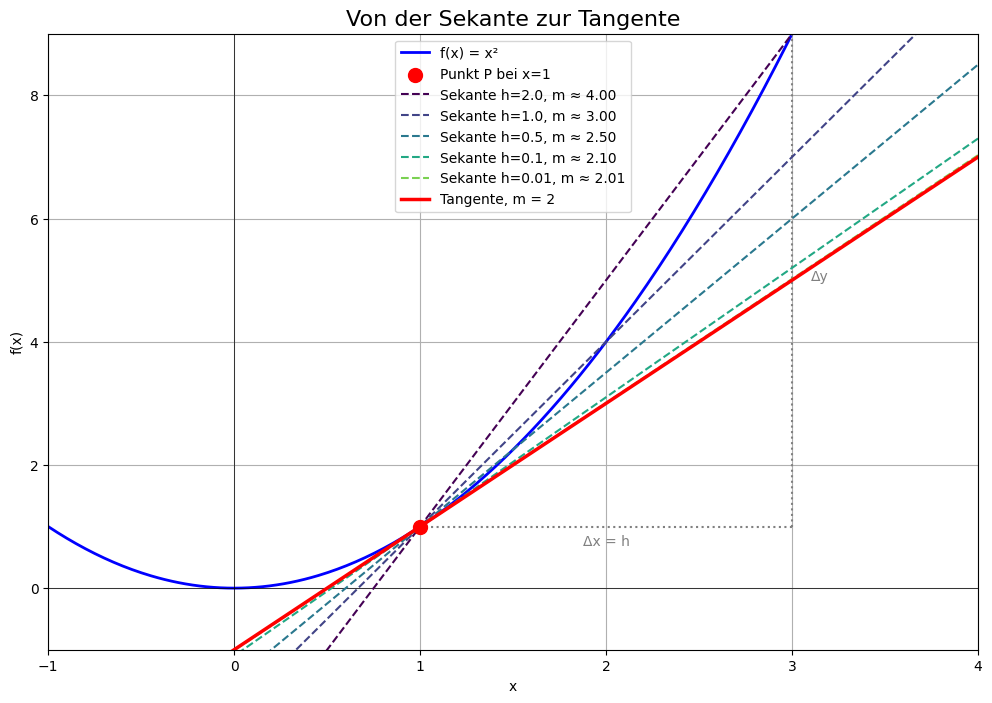

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- Konfiguration ---
Sekanten_Config = {
    "funktion": lambda x: x**2,           # f(x) = x²
    "x_punkt": 1,                           # Punkt, an dem wir die Steigung suchen
    "h_werte": [2.0, 1.0, 0.5, 0.1, 0.01], # Abstände h (von grob bis fein)
    "x_bereich": (-1, 4),
    "y_bereich": (-1, 9),
    "figsize": (12, 8),
}

def visualisiere_sekanten_zu_tangente(config):
    """Visualisiert den Übergang von Sekantenlinien zur Tangente."""
    f = config["funktion"]
    x_p = config["x_punkt"]
    h_werte = config["h_werte"]

    x_vals = np.linspace(*config["x_bereich"], 400)
    y_vals = f(x_vals)
    P = (x_p, f(x_p))

    fig, ax = plt.subplots(figsize=config["figsize"])
    ax.plot(x_vals, y_vals, label="f(x) = x²", color='blue', linewidth=2)
    ax.set_title("Von der Sekante zur Tangente", fontsize=16)
    ax.grid(True)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)

    # Punkt P einzeichnen
    ax.scatter(*P, color='red', s=100, zorder=5, label=f"Punkt P bei x={x_p}")

    # Sekanten zeichnen für verschiedene h-Werte
    for i, h in enumerate(h_werte):
        Q = (x_p + h, f(x_p + h))
        sekanten_steigung = (Q[1] - P[1]) / (Q[0] - P[0])

        # Steigungsdreieck einzeichnen (nur für den größten h-Wert)
        if i == 0:
            ax.plot([P[0], Q[0]], [P[1], P[1]], color='gray', linewidth=1.5, linestyle=':')
            ax.plot([Q[0], Q[0]], [P[1], Q[1]], color='gray', linewidth=1.5, linestyle=':')
            ax.annotate('Δx = h', xy=((P[0]+Q[0])/2, P[1]-0.3), fontsize=10, ha='center', color='gray')
            ax.annotate('Δy', xy=(Q[0]+0.1, (P[1]+Q[1])/2), fontsize=10, color='gray')

        # Sekantenlinie
        sekanten_gerade = lambda x, m=sekanten_steigung: m * (x - P[0]) + P[1]
        farbe = plt.cm.viridis(i / len(h_werte))
        ax.plot(x_vals, sekanten_gerade(x_vals), linestyle='--', color=farbe,
                label=f"Sekante h={h}, m ≈ {sekanten_steigung:.2f}")

    # Wahre Tangente (Ableitung von x² ist 2x, bei x=1: m=2)
    tangenten_steigung = 2 * x_p
    tangenten_gerade = lambda x: tangenten_steigung * (x - P[0]) + P[1]
    ax.plot(x_vals, tangenten_gerade(x_vals), color='red', linewidth=2.5,
            label=f"Tangente, m = {tangenten_steigung}")

    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_ylim(*config["y_bereich"])
    ax.set_xlim(*config["x_bereich"])
    ax.legend()
    plt.show()

visualisiere_sekanten_zu_tangente(Sekanten_Config)

### 2. Die Ableitung berechnen: Die Grenzwertdefinition

Der obige Prozess wird durch die **Grenzwertdefinition der Ableitung** formalisiert:

$$
f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}
$$

Die Notation $f'(x)$ (gesprochen: „f Strich von x") ist eine der üblichen Schreibweisen. Die wichtigsten Notationen sind:

| Notation | Name | Wann verwendet |
|----------|------|---------------|
| $f'(x)$ | Lagrange-Notation | Am häufigsten in der Schulmathematik |
| $\frac{df}{dx}$ oder $\frac{dy}{dx}$ | Leibniz-Notation | Betont die Variablen, nützlich bei Kettenregel |
| $\dot{f}$ | Newton-Notation | Vor allem in der Physik (Ableitung nach der Zeit) |

Machen wir daraus eine Python-Funktion! Wir können $h$ nicht wirklich Null setzen (Division durch Null!), aber wir können es sehr klein machen, z.B. $h = 1 \cdot 10^{-7}$.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --- Unsere Funktionen ---
def f1(x):
    """f(x) = x²"""
    return x**2

def f2(x):
    """g(x) = x³ + 2x"""
    return x**3 + 2*x

# --- Numerische Ableitung ---
def numerische_ableitung(func, x, h=1e-7):
    """
    Berechnet die numerische Ableitung einer Funktion 'func' an der Stelle 'x'.

    Parameter:
        func (function): Die Funktion, die abgeleitet werden soll
        x (float): Die Stelle, an der die Ableitung berechnet wird
        h (float): Sehr kleine Zahl zur Annäherung an den Grenzwert

    Rückgabe:
        Die ungefähre Steigung der Tangente an der Stelle x.
    """
    return (func(x + h) - func(x)) / h

# --- Tests ---
# Ableitung von f1(x) = x² an der Stelle x=1 (exakt: 2·1 = 2)
abl_bei_1 = numerische_ableitung(f1, 1)
print(f"Ableitung von f(x)=x² bei x=1: {abl_bei_1:.6f}  (exakt: 2)")

# Ableitung von f1(x) = x² an der Stelle x=3 (exakt: 2·3 = 6)
abl_bei_3 = numerische_ableitung(f1, 3)
print(f"Ableitung von f(x)=x² bei x=3: {abl_bei_3:.6f}  (exakt: 6)")

# Ableitung von f2(x) = x³+2x bei x=2 (exakt: 3·4+2 = 14)
abl_f2_bei_2 = numerische_ableitung(f2, 2)
print(f"Ableitung von g(x)=x³+2x bei x=2: {abl_f2_bei_2:.6f}  (exakt: 14)")

Ableitung von f(x)=x² bei x=1: 2.000000  (exakt: 2)
Ableitung von f(x)=x² bei x=3: 6.000000  (exakt: 6)
Ableitung von g(x)=x³+2x bei x=2: 14.000001  (exakt: 14)


Bei x=1.0: Punkt (1.00, 1.00), Steigung ≈ 2.00
Bei x=3.0: Punkt (3.00, 9.00), Steigung ≈ 6.00
Bei x=2.0: Punkt (2.00, 12.00), Steigung ≈ 14.00


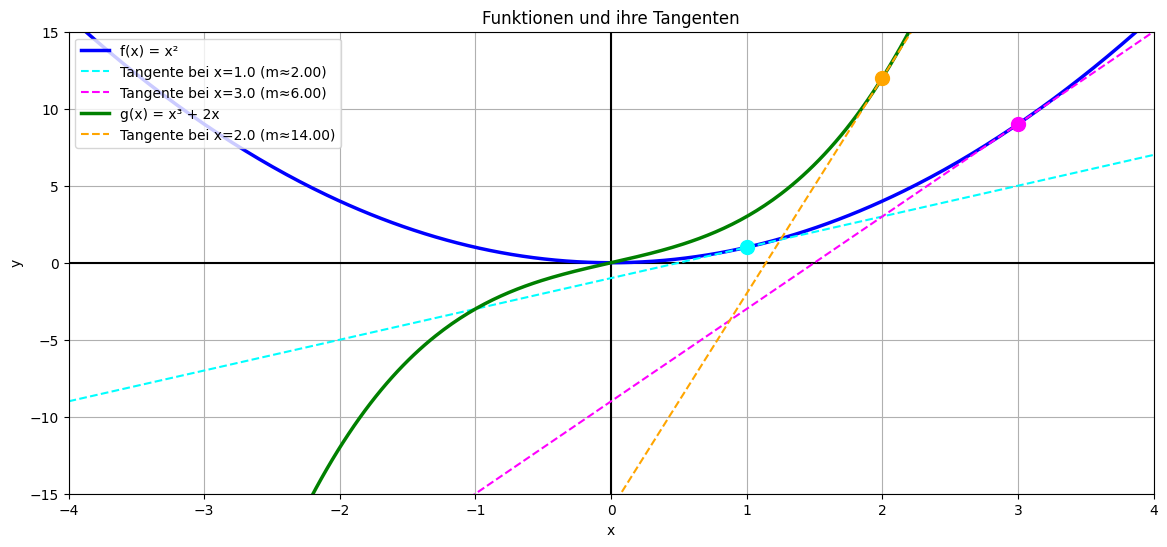

In [7]:
# --- Tangenten-Visualisierung ---

Tangenten_Config = {
    "funktionen": [
        {"func": f1, "label": "f(x) = x²", "farbe": "blue", "tangenten": [
            {"x": 1.0, "farbe": "cyan"},
            {"x": 3.0, "farbe": "magenta"},
        ]},
        {"func": f2, "label": "g(x) = x³ + 2x", "farbe": "green", "tangenten": [
            {"x": 2.0, "farbe": "orange"},
        ]},
    ],
    "x_bereich": (-4, 4),
    "y_bereich": (-15, 15),
    "figsize": (14, 6),
}

def zeichne_tangenten(config):
    """Zeichnet Funktionen mit ihren Tangenten an gegebenen Stellen."""
    x_vals = np.linspace(*config["x_bereich"], 400)

    plt.figure(figsize=config["figsize"])
    plt.grid(True)
    plt.axhline(0, color='black', linewidth=1.5)
    plt.axvline(0, color='black', linewidth=1.5)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Funktionen und ihre Tangenten")

    for fn_info in config["funktionen"]:
        func = fn_info["func"]
        y_vals = func(x_vals)
        plt.plot(x_vals, y_vals, label=fn_info["label"], color=fn_info["farbe"], linewidth=2.5)

        for tang in fn_info["tangenten"]:
            x_p = tang["x"]
            y_p = func(x_p)
            steigung = numerische_ableitung(func, x_p)
            tangenten_linie = steigung * (x_vals - x_p) + y_p

            print(f"Bei x={x_p}: Punkt ({x_p:.2f}, {y_p:.2f}), Steigung ≈ {steigung:.2f}")

            plt.scatter(x_p, y_p, color=tang["farbe"], s=100, zorder=5)
            plt.plot(x_vals, tangenten_linie, color=tang["farbe"], linestyle='--',
                     label=f"Tangente bei x={x_p} (m≈{steigung:.2f})")

    plt.xlim(*config["x_bereich"])
    plt.ylim(*config["y_bereich"])
    plt.legend(loc="upper left")
    plt.show()

zeichne_tangenten(Tangenten_Config)

### 3. Die exakte Ableitung mit SymPy

Unsere `numerische_ableitung`-Funktion ist nützlich für die Intuition, aber sie liefert nur eine **Näherung**. Für exakte Ergebnisse brauchen wir symbolische Mathematik. Das geht mit der Bibliothek `sympy`. Sie behandelt Variablen als Symbole, nicht als Zahlen.

Lass uns SymPy nutzen, um die Ableitung von $f(x) = x^2$ exakt zu berechnen:

In [8]:
import sympy as sp

# 1. Variable als mathematisches Symbol deklarieren
x = sp.Symbol('x')

# 2. Funktion symbolisch definieren
f_sym = x**2

# 3. Ableitung berechnen mit sp.diff()
f_abl = sp.diff(f_sym, x)

print(f"Die Funktion ist:  f(x) = {f_sym}")
print(f"Die Ableitung ist: f'(x) = {f_abl}")

# Noch ein Beispiel: g(x) = x³ + 2x
g_sym = x**3 + 2*x
g_abl = sp.diff(g_sym, x)

print(f"\nDie Funktion ist:  g(x) = {g_sym}")
print(f"Die Ableitung ist: g'(x) = {g_abl}")

# Wert der Ableitung an einer Stelle berechnen
g_abl_bei_2 = g_abl.subs(x, 2)
print(f"\ng'(2) = {g_abl_bei_2}  (das bestätigt unsere numerische Berechnung!)")

Die Funktion ist:  f(x) = x**2
Die Ableitung ist: f'(x) = 2*x

Die Funktion ist:  g(x) = x**3 + 2*x
Die Ableitung ist: g'(x) = 3*x**2 + 2

g'(2) = 14  (das bestätigt unsere numerische Berechnung!)


---

### Verständnis-Check 
*Diese Aufgaben sind zum Üben auf Papier gedacht!*

**Aufgabe 1:** Berechne den Differenzenquotienten für $f(x) = x^2$ zwischen $x = 2$ und $x = 2{,}5$.
$$\frac{f(2{,}5) - f(2)}{2{,}5 - 2} = \frac{? - ?}{?} = \, ?$$

**Aufgabe 2:** Berechne die Ableitung $f'(x)$ für $f(x) = x^2$ an der Stelle $x = 3$ mit der Grenzwertdefinition. (Setze $f(x+h)$ ein und vereinfache!)

**Aufgabe 3:** Gegeben ist $f(x) = 3x^2 + 4x - 1$. Berechne den Differenzenquotienten für $x = 1$ und $h = 0{,}1$.

**Aufgabe 4:** Welche Steigung hat die Tangente an $f(x) = x^3$ bei $x = 2$? (Benutze die Grenzwertdefinition oder SymPy.)

### Lösungen

**Lösung 1:**
$$\frac{f(2{,}5) - f(2)}{0{,}5} = \frac{6{,}25 - 4}{0{,}5} = \frac{2{,}25}{0{,}5} = 4{,}5$$

**Lösung 2:**
$$f'(3) = \lim_{h \to 0} \frac{(3+h)^2 - 9}{h} = \lim_{h \to 0} \frac{9 + 6h + h^2 - 9}{h} = \lim_{h \to 0} \frac{6h + h^2}{h} = \lim_{h \to 0} (6 + h) = 6$$

**Lösung 3:**
$$\frac{f(1{,}1) - f(1)}{0{,}1} = \frac{3(1{,}21) + 4(1{,}1) - 1 - (3 + 4 - 1)}{0{,}1} = \frac{7{,}03 - 6}{0{,}1} = 10{,}3$$

**Lösung 4:**
$$f'(x) = 3x^2 \Rightarrow f'(2) = 3 \cdot 4 = 12$$

---

### Zusammenfassung

In diesem Abschnitt hast Du gelernt:
- Die Ableitung beschreibt die **momentane Steigung** einer Kurve an einem Punkt
- Der Übergang von **Sekante** (Durchschnittssteigung) zu **Tangente** (Momentansteigung) erfolgt durch den Grenzwert $h \to 0$
- Der **Differenzenquotient** $\frac{f(x+h)-f(x)}{h}$ nähert die Ableitung an
- Die **Grenzwertdefinition** $f'(x) = \lim_{h \to 0} \frac{f(x+h)-f(x)}{h}$ ist die exakte Definition
- **SymPy** kann Ableitungen symbolisch (exakt) berechnen

Im nächsten Abschnitt lernst Du die wichtigsten **Ableitungsregeln**, mit denen Du Ableitungen schnell auf Papier berechnen kannst.

---

### Glossar (Deutsch - Englisch)

| Deutsch | Englisch |
|---------|----------|
| Ableitung | Derivative |
| Steigung | Slope |
| Tangente | Tangent (line) |
| Sekante | Secant (line) |
| Steigungsdreieck | Slope triangle |
| Differenzenquotient | Difference quotient |
| Grenzwert | Limit |
| Momentane Änderungsrate | Instantaneous rate of change |
| Durchschnittliche Änderungsrate | Average rate of change |